# Random Forest Machine Learning Project
## Titanic Survival Prediction (Classification)
**Student:** ____________________  **Date:** ____________

**Dataset:** Titanic - Machine Learning from Disaster (`train.csv`, 891 rows) - Kaggle: https://www.kaggle.com/c/titanic/data  
**Problem Statement:** Predict whether a passenger survived (`Survived`: 1 = survived, 0 = did not) from passenger details such as class, sex, age, family size and fare.  
**Model:** Random Forest Classifier

## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
sns.set_style('whitegrid')

## 2. Load the Dataset

In [2]:
# Real-world Kaggle dataset (train.csv from the Titanic competition) - not synthetic
df = pd.read_csv('titanic.csv')
print('Shape:', df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Basic Data Exploration

In [3]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [4]:
print('Missing values per column:\n', df.isnull().sum())
print('\nTarget distribution:\n', df['Survived'].value_counts())

Missing values per column:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Target distribution:
 Survived
0    549
1    342
Name: count, dtype: int64


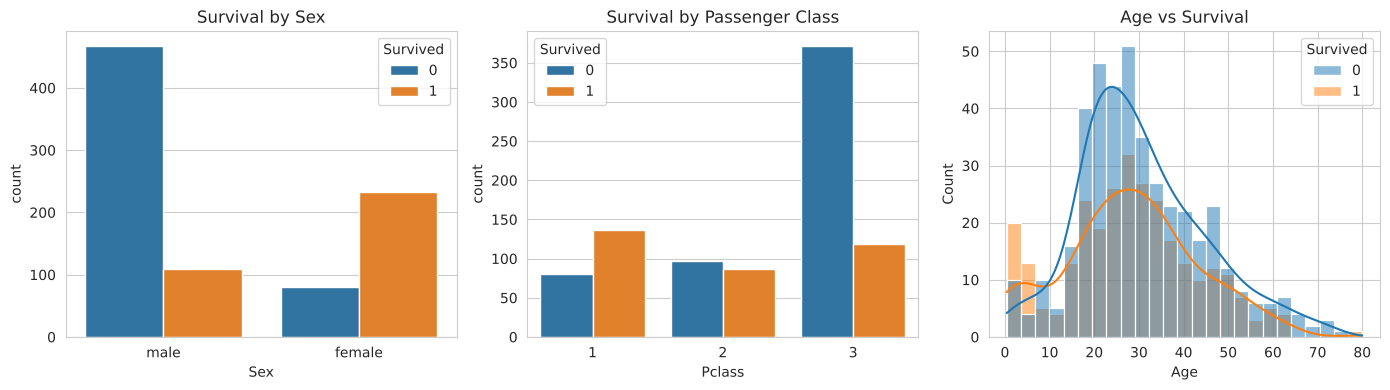

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.countplot(data=df, x='Sex', hue='Survived', ax=ax[0]); ax[0].set_title('Survival by Sex')
sns.countplot(data=df, x='Pclass', hue='Survived', ax=ax[1]); ax[1].set_title('Survival by Passenger Class')
sns.histplot(data=df, x='Age', hue='Survived', bins=25, kde=True, ax=ax[2]); ax[2].set_title('Age vs Survival')
plt.tight_layout(); plt.show()

## 4. Handle Missing Values
- `Age` (177 missing) → filled with the **median** (robust to outliers)
- `Embarked` (2 missing) → filled with the **mode** (most common port)
- `Cabin` (687 missing, ~77%) → **dropped**, too sparse to be useful
- `PassengerId`, `Name`, `Ticket` → dropped (identifiers with no predictive pattern for this simple model)

In [6]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df = df.drop(columns=['Cabin', 'PassengerId', 'Name', 'Ticket'])

# Feature engineering: family size is more informative than SibSp/Parch separately
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
print('Remaining missing values:', df.isnull().sum().sum())
df.head()

Remaining missing values: 0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize
0,0,3,male,22.0,1,0,7.2500,S,2
1,1,1,female,38.0,1,0,71.2833,C,2
2,1,3,female,26.0,0,0,7.9250,S,1
3,1,1,female,35.0,1,0,53.1000,S,2
4,0,3,male,35.0,0,0,8.0500,S,1


## 5. Encode Categorical Variables

In [7]:
# Sex -> binary; Embarked -> one-hot encoding (drop_first avoids redundant column)
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True, dtype=int)
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,2,0,1
1,1,1,1,38.0,1,0,71.2833,2,0,0
2,1,3,1,26.0,0,0,7.9250,1,0,1
3,1,1,1,35.0,1,0,53.1000,2,0,1
4,0,3,0,35.0,0,0,8.0500,1,0,1


## 6. Split Features (X) and Target (y)

In [8]:
X = df.drop(columns='Survived')
y = df['Survived']
print('Features:', list(X.columns))

Features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'Embarked_Q', 'Embarked_S']


## 7. Train-Test Split
80% training / 20% testing, stratified to keep the same survival ratio in both sets.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (712, 9)  Test: (179, 9)


## 8-9. Apply and Train the Random Forest Model

In [10]:
# Baseline Random Forest (scaling is not required for tree-based models)
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
print('Baseline model trained.')

Baseline model trained.


## 10. Make Predictions

In [11]:
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]
pd.DataFrame({'Actual': y_test.values[:10], 'Predicted': y_pred[:10]})

,Actual,Predicted
0,0,0
1,0,0
2,1,0
3,0,0
4,1,1
5,1,0
6,1,1
7,0,1
8,0,1
9,0,0


## 11. Evaluate the Model

In [12]:
results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Result': [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
               recall_score(y_test, y_pred), f1_score(y_test, y_pred),
               roc_auc_score(y_test, y_prob)]
}).round(3)
display(results)
print(classification_report(y_test, y_pred, target_names=['Died', 'Survived']))

,Metric,Result
0,Accuracy,0.816
1,Precision,0.781
2,Recall,0.725
3,F1-Score,0.752
4,ROC-AUC,0.835


              precision    recall  f1-score   support

        Died       0.83      0.87      0.85       110
    Survived       0.78      0.72      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



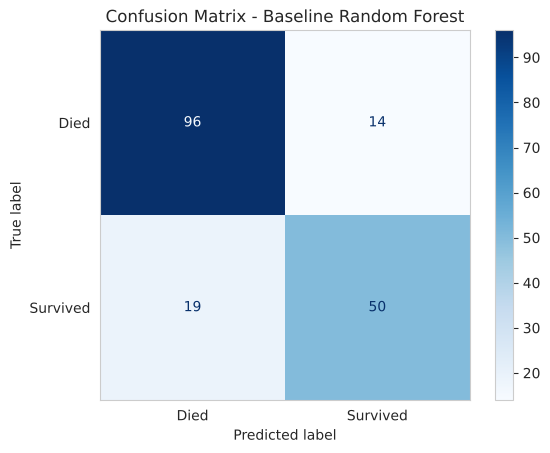

TN = 96, FP = 14, FN = 19, TP = 50


In [13]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Died', 'Survived']).plot(cmap='Blues')
plt.title('Confusion Matrix - Baseline Random Forest'); plt.grid(False); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f'TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}')

## 12. Feature Importance

,Importance
Sex,0.275
Fare,0.258
Age,0.240
Pclass,0.086
FamilySize,0.053
SibSp,0.029
Embarked_S,0.025
Parch,0.023
Embarked_Q,0.010


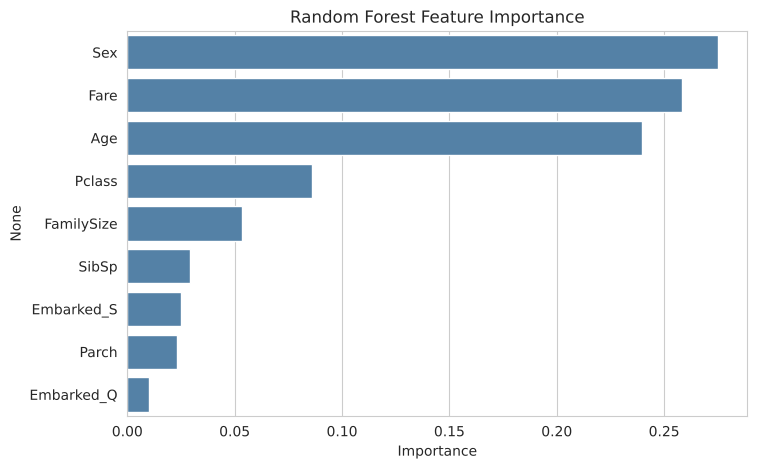

In [14]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
display(imp.round(3).to_frame('Importance'))
plt.figure(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color='steelblue')
plt.title('Random Forest Feature Importance'); plt.xlabel('Importance'); plt.show()

## Bonus A: Cross-Validation
5-fold cross-validation gives a more reliable estimate than a single split.

In [15]:
cv_scores = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=42), X, y, cv=5, scoring='accuracy')
print('CV accuracy per fold:', cv_scores.round(3))
print(f'Mean CV accuracy: {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})')

CV accuracy per fold: [0.782 0.809 0.86  0.781 0.831]
Mean CV accuracy: 0.813 (+/- 0.030)


## Bonus B: Hyperparameter Tuning (GridSearchCV)

In [16]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid,
                    cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)
print('Best parameters:', grid.best_params_)
print(f'Best CV accuracy (train only): {grid.best_score_:.3f}')

Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}
Best CV accuracy (train only): 0.827


In [17]:
best_rf = grid.best_estimator_
yb_pred = best_rf.predict(X_test)
yb_prob = best_rf.predict_proba(X_test)[:, 1]
compare = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Baseline RF': [accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
                    recall_score(y_test, y_pred), f1_score(y_test, y_pred), roc_auc_score(y_test, y_prob)],
    'Tuned RF': [accuracy_score(y_test, yb_pred), precision_score(y_test, yb_pred),
                 recall_score(y_test, yb_pred), f1_score(y_test, yb_pred), roc_auc_score(y_test, yb_prob)]
}).round(3)
compare

,Metric,Baseline RF,Tuned RF
0,Accuracy,0.816,0.804
1,Precision,0.781,0.804
2,Recall,0.725,0.652
3,F1-Score,0.752,0.720
4,ROC-AUC,0.835,0.834


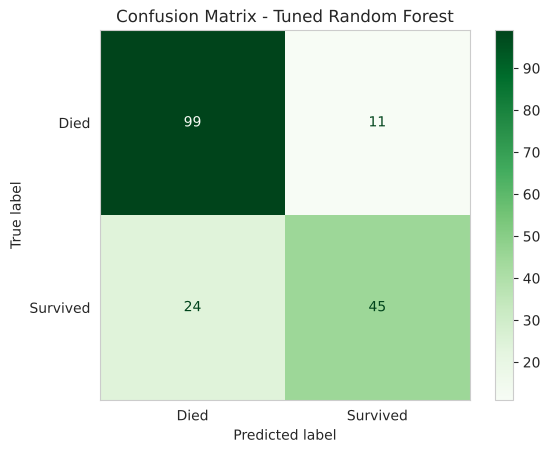

,Tuned Importance
Sex,0.366
Fare,0.213
Age,0.169
Pclass,0.110
FamilySize,0.054
SibSp,0.030
Embarked_S,0.026
Parch,0.022
Embarked_Q,0.009


In [18]:
cm2 = confusion_matrix(y_test, yb_pred)
ConfusionMatrixDisplay(cm2, display_labels=['Died', 'Survived']).plot(cmap='Greens')
plt.title('Confusion Matrix - Tuned Random Forest'); plt.grid(False); plt.show()
imp2 = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
display(imp2.round(3).to_frame('Tuned Importance'))

## Bonus C: Save the Model with Joblib

In [19]:
joblib.dump(best_rf, 'titanic_random_forest.joblib')
loaded = joblib.load('titanic_random_forest.joblib')
print('Reloaded model accuracy on test set:', round(accuracy_score(y_test, loaded.predict(X_test)), 3))

Reloaded model accuracy on test set: 0.804


## 13. Conclusion
*(Write your conclusion in your own words here.)*

Points to cover: which metrics were best/worst and why; which features mattered most (Sex, Fare, Age, Pclass...) and whether that makes sense historically; whether tuning helped; limitations (small dataset, dropped Cabin) and what you would try next.